In [4]:
import yfinance as yf

In [5]:
sp500 =yf.Ticker("^GSPC")

In [10]:
sp500 = sp500.history(period="max")

In [11]:
sp500

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
1927-12-30 00:00:00-05:00,17.660000,17.660000,17.660000,17.660000,0,0.0,0.0
1928-01-03 00:00:00-05:00,17.760000,17.760000,17.760000,17.760000,0,0.0,0.0
1928-01-04 00:00:00-05:00,17.719999,17.719999,17.719999,17.719999,0,0.0,0.0
1928-01-05 00:00:00-05:00,17.549999,17.549999,17.549999,17.549999,0,0.0,0.0
1928-01-06 00:00:00-05:00,17.660000,17.660000,17.660000,17.660000,0,0.0,0.0
...,...,...,...,...,...,...,...
2026-10-19 00:00:00-04:00,7702.770020,7731.180176,7684.790039,7690.729980,4587260000,0.0,0.0
2026-10-20 00:00:00-04:00,7679.009766,7748.419922,7668.029785,7712.569824,5004770000,0.0,0.0
2026-10-21 00:00:00-04:00,7736.430176,7770.399902,7709.339844,7757.169922,4921480000,0.0,0.0


In [12]:
sp500.index

DatetimeIndex(['1927-12-30 00:00:00-05:00', '1928-01-03 00:00:00-05:00',
               '1928-01-04 00:00:00-05:00', '1928-01-05 00:00:00-05:00',
               '1928-01-06 00:00:00-05:00', '1928-01-09 00:00:00-05:00',
               '1928-01-10 00:00:00-05:00', '1928-01-11 00:00:00-05:00',
               '1928-01-12 00:00:00-05:00', '1928-01-13 00:00:00-05:00',
               ...
               '2026-10-12 00:00:00-04:00', '2026-10-13 00:00:00-04:00',
               '2026-10-14 00:00:00-04:00', '2026-10-15 00:00:00-04:00',
               '2026-10-16 00:00:00-04:00', '2026-10-19 00:00:00-04:00',
               '2026-10-20 00:00:00-04:00', '2026-10-21 00:00:00-04:00',
               '2026-10-22 00:00:00-04:00', '2026-10-23 00:00:00-04:00'],
              dtype='datetime64[s, America/New_York]', name='Date', length=24821, freq=None)

<Axes: xlabel='Date'>

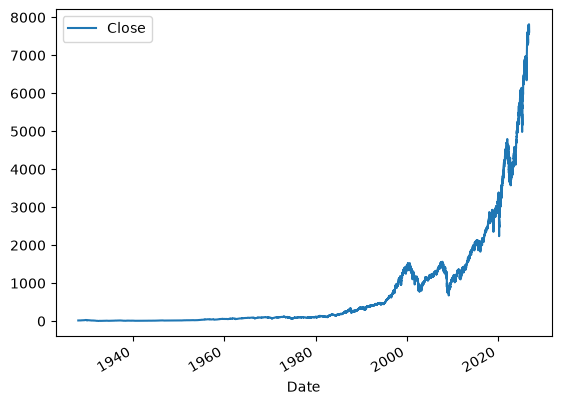

In [17]:
sp500.plot.line(y="Close", use_index=True)

In [19]:
del sp500["Dividends"]
del sp500["Stock Splits"]

In [22]:
sp500["Tomorrow"] = sp500["Close"].shift(-1)

#what this is doing it is taking the close of the day after and is showing us that this is 
#going to be the opening price for this time 

In [23]:
sp500

,Open,High,Low,Close,Volume,Tomorrow
Date,,,,,,
1927-12-30 00:00:00-05:00,17.660000,17.660000,17.660000,17.660000,0,17.760000
1928-01-03 00:00:00-05:00,17.760000,17.760000,17.760000,17.760000,0,17.719999
1928-01-04 00:00:00-05:00,17.719999,17.719999,17.719999,17.719999,0,17.549999
1928-01-05 00:00:00-05:00,17.549999,17.549999,17.549999,17.549999,0,17.660000
1928-01-06 00:00:00-05:00,17.660000,17.660000,17.660000,17.660000,0,17.500000
...,...,...,...,...,...,...
2026-10-19 00:00:00-04:00,7702.770020,7731.180176,7684.790039,7690.729980,4587260000,7712.569824
2026-10-20 00:00:00-04:00,7679.009766,7748.419922,7668.029785,7712.569824,5004770000,7757.169922
2026-10-21 00:00:00-04:00,7736.430176,7770.399902,7709.339844,7757.169922,4921480000,7663.430176


In [26]:
sp500["Target"] = (sp500["Tomorrow"] > sp500["Close"]).astype(int)

#this will return a booleon indicating if tomorrow price is greate
#since we want to use it in ML we convert it into a int

In [27]:
sp500

#the 1 shows when tomorrows price is greater than todays price(open)

,Open,High,Low,Close,Volume,Tomorrow,Target
Date,,,,,,,
1927-12-30 00:00:00-05:00,17.660000,17.660000,17.660000,17.660000,0,17.760000,1
1928-01-03 00:00:00-05:00,17.760000,17.760000,17.760000,17.760000,0,17.719999,0
1928-01-04 00:00:00-05:00,17.719999,17.719999,17.719999,17.719999,0,17.549999,0
1928-01-05 00:00:00-05:00,17.549999,17.549999,17.549999,17.549999,0,17.660000,1
1928-01-06 00:00:00-05:00,17.660000,17.660000,17.660000,17.660000,0,17.500000,0
...,...,...,...,...,...,...,...
2026-10-19 00:00:00-04:00,7702.770020,7731.180176,7684.790039,7690.729980,4587260000,7712.569824,1
2026-10-20 00:00:00-04:00,7679.009766,7748.419922,7668.029785,7712.569824,5004770000,7757.169922,1
2026-10-21 00:00:00-04:00,7736.430176,7770.399902,7709.339844,7757.169922,4921480000,7663.430176,0


In [28]:
sp500 = sp500.loc["1990-01-01":].copy()

#so with .loc we locate dates only to be used from 1990-01-01 and we use a copy for
#pandas when we try to subset a data frame and later asign back to it, basically a new copy

In [29]:
sp500

,Open,High,Low,Close,Volume,Tomorrow,Target
Date,,,,,,,
1990-01-02 00:00:00-05:00,353.399994,359.690002,351.980011,359.690002,162070000,358.760010,0
1990-01-03 00:00:00-05:00,359.690002,360.589996,357.890015,358.760010,192330000,355.670013,0
1990-01-04 00:00:00-05:00,358.760010,358.760010,352.890015,355.670013,177000000,352.200012,0
1990-01-05 00:00:00-05:00,355.670013,355.670013,351.350006,352.200012,158530000,353.790009,1
1990-01-08 00:00:00-05:00,352.200012,354.239990,350.540009,353.790009,140110000,349.619995,0
...,...,...,...,...,...,...,...
2026-10-19 00:00:00-04:00,7702.770020,7731.180176,7684.790039,7690.729980,4587260000,7712.569824,1
2026-10-20 00:00:00-04:00,7679.009766,7748.419922,7668.029785,7712.569824,5004770000,7757.169922,1
2026-10-21 00:00:00-04:00,7736.430176,7770.399902,7709.339844,7757.169922,4921480000,7663.430176,0


In [32]:
from sklearn.ensemble import RandomForestClassifier

#RFC works by training a bunch of individual decison trees with randomised paramaters
#and then averageing the result from those decison trees so resistant to overfitting
#they can overfit/split but harder than other models and run quickly and pick up non-linear data
#such as oepn price for one being 70000 330

model = RandomForestClassifier(n_estimators=100, min_samples_split=100, random_state=1)

#n_estimators is the number of decison trees we want to train, more = more accuracy to a limit
#min_sample_split If a tree oversplits, it stops learning actual market trends and instead
#just memorizes the past. It becomes a genius at explaining what happened in 1995, 
#but it fails completely when trying to predict tomorrow because tomorrow won't match 
#those hyper-specific past quirks. Higher we set less accurate but less it will fit.
#random_state , random forest has some randomisation in it so the numbers generated will 
#be in a predictable sequcence so if ran twice it will be same helps with updating modle

# 1. Split the data to create our training set (all rows EXCEPT the last 100)
# The model will study this historical data to learn patterns.

train = sp500.iloc[:-100]
#2. Split the data to create our test set (ONLY the last 100 rows)
# We keep these 100 rows hidden from the model so we can test it later.

test=sp500.iloc[-100:]
# 3. Define our predictors (the input columns the model is allowed to look at)
# These are the historical numbers we think will help predict tomorrow's movement.

predictors = ["Close", "Volume" , "Open" , "High" , "Low"]

# 4. Train (fit) the machine learning model
# We give it the training inputs (predictors) and the correct answers (Target: 0 or 1),
# and the Random Forest algorithm figures out the relationships between them.

model.fit(train[predictors], train["Target"])


,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",100
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootst

In [33]:
from sklearn.metrics import precision_score

#pre_score is when we said when the market will go up when it was a 1, what % of time does
#it go up

preds = model.predict(test[predictors])

In [35]:
preds

#gives it as a numpy array so we make it into a pandas series

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [39]:
import pandas as pd
preds = pd.Series(preds, index=test.index)

In [40]:
preds

Date
2026-06-03 00:00:00-04:00    1
2026-06-04 00:00:00-04:00    1
2026-06-05 00:00:00-04:00    1
2026-06-08 00:00:00-04:00    1
2026-06-09 00:00:00-04:00    1
                            ..
2026-10-19 00:00:00-04:00    1
2026-10-20 00:00:00-04:00    1
2026-10-21 00:00:00-04:00    1
2026-10-22 00:00:00-04:00    1
2026-10-23 00:00:00-04:00    1
Length: 100, dtype: int64

In [42]:
precision_score(test["Target"], preds)

0.45

In [43]:
combined = pd.concat([test["Target"], preds], axis =1)
# pd.concat joins multiple Pandas objects (DataFrames or Series) together
# First item to glue: the actual true answers from our test dataset ("Target")
# Second item to glue: our model's predictions (preds)
# axis=1 tells Pandas to glue them side-by-side as separate columns
# (instead of stacking them vertically on top of each other)

<Axes: xlabel='Date'>

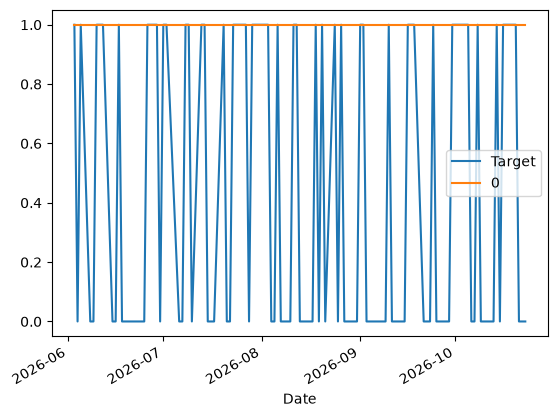

In [44]:
combined.plot()

In [57]:
def predict(train, test, predictors, model):
    model.fit(train[predictors], train["Target"])
    preds = model.predict(test[predictors])
    preds=pd.Series(preds, index=test.index, name="Predictions")
    combined = pd.concat([test["Target"], preds], axis =1)
    return combined

# Define a custom function named 'predict' that takes four inputs: 
# training data, test data, our predictor columns, and the machine learning model
# Train the model using the training data features and their matching answers ("Target")
# Generate model predictions for our test data and store them in a variable called 'preds'
# Convert the raw NumPy array of predictions into a Pandas Series, 
# line up its row labels (index) with the test set, and name the column "Predictions"
# Return the final predictions Series so we can use it later

In [58]:

#tricky
#2500 as each year has 250 days of trading days , steps is 250 as we are trainingthat much for a
#year this way we can train for 10 find for 11 trian for 11 yr find for 12 etc

def backtest(data, model, predictors, start=2500, step=250):
    # All of this code needs to be indented by one tab!
    all_predictions = []

    for i in range(start, data.shape[0], step):
        train = data.iloc[0:i].copy()
        test = data.iloc[i : (i + step)].copy()
        predictions = predict(train, test, predictors, model)
        all_predictions.append(predictions)

    return pd.concat(all_predictions)

In [59]:
predictions = backtest(sp500, model, predictors)

In [60]:
predictions["Predictions"].value_counts()

Predictions
0    4082
1    2689
Name: count, dtype: int64

In [63]:
precision_score(predictions["Target"], predictions["Predictions"])

0.5314243213090368

In [66]:
predictions["Target"].value_counts() / predictions.shape[0]

Target
1    0.536701
0    0.463299
Name: count, dtype: float64

In [95]:
horizons = [2,5,60,250,1000]

new_predictors = ["Close", "Volume", "Open", "High", "Low"]

new_predictors += [f"Close_Ratio_{h}" for h in horizons]
new_predictors += [f"Trend_{h}" for h in horizons]
# horizons are rolling means for clsoe price for 2 days , 5 days .. etc


new_predictors = []

for horizon in horizons:
    rolling_averages = sp500.rolling(horizon).mean()

    ratio_column = f"Close_Ratio_{horizon}"
    sp500[ratio_column] = sp500["Close"] / rolling_averages["Close"]

    trend_column = f"Trend_{horizon}"
    sp500[trend_column] = sp500.shift(1).rolling(horizon).sum()["Target"]

    new_predictors += [ratio_column, trend_column]



In [96]:
sp500 = sp500.dropna()

In [97]:
sp500

,Open,High,Low,Close,Volume,Tomorrow,Target,Close_Ratio_2,Trend_2,Close_Ratio_5,Trend_5,Close_Ratio_60,Trend_60,Close_Ratio_250,Trend_250,Close_Ratio_1000,Trend_1000
Date,,,,,,,,,,,,,,,,,
1997-11-26 00:00:00-05:00,950.820007,956.469971,950.820007,951.640015,487750000,955.400024,1,1.000431,2.0,0.997275,4.0,1.009111,33.0,1.113282,138.0,1.517046,563.0
1997-11-28 00:00:00-05:00,951.640015,959.130005,951.640015,955.400024,189070000,974.770020,1,1.001972,2.0,1.001967,4.0,1.012659,33.0,1.116599,139.0,1.521842,564.0
1997-12-01 00:00:00-05:00,955.400024,974.770020,955.400024,974.770020,590300000,971.679993,0,1.010035,2.0,1.019783,4.0,1.032356,34.0,1.138015,140.0,1.551433,564.0
1997-12-02 00:00:00-05:00,974.780029,976.200012,969.830017,971.679993,576120000,976.770020,1,0.998412,1.0,1.011259,4.0,1.028349,33.0,1.133204,140.0,1.545272,563.0
1997-12-03 00:00:00-05:00,971.679993,980.809998,966.159973,976.770020,624610000,973.099976,0,1.002612,1.0,1.011095,4.0,1.032949,33.0,1.137882,141.0,1.552105,564.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-16 00:00:00-04:00,7745.319824,7756.839844,7631.770020,7659.439941,5482060000,7690.729980,1,0.994506,1.0,0.988694,1.0,0.997780,27.0,1.067188,132.0,1.360045,547.0
2026-10-19 00:00:00-04:00,7702.770020,7731.180176,7684.790039,7690.729980,4587260000,7712.569824,1,1.002038,1.0,0.995728,2.0,1.001250,27.0,1.070977,132.0,1.364647,547.0
2026-10-20 00:00:00-04:00,7679.009766,7748.419922,7668.029785,7712.569824,5004770000,7757.169922,1,1.001418,2.0,1.000963,3.0,1.003442,27.0,1.073434,132.0,1.367572,547.0


In [98]:
model = RandomForestClassifier(n_estimators=200, min_samples_split=50, random_state=1)

In [99]:
def predict(train, test, predictors, model):
    model.fit(train[predictors], train["Target"])
    preds = model.predict_proba(test[predictors])[:,1]
    preds[preds >= .6] = 1
    preds[preds < .6] = 0
    preds = pd.Series(preds, index=test.index, name="Predictions")
    combined = pd.concat([test["Target"], preds], axis =1)
    return combined

    #setting to 0.6 so that we know the model is more confident it will go up and inc chance it does

In [103]:
predictions = backtest(sp500, model, new_predictors)

In [106]:
predictions["Predictions"].value_counts()

Predictions
0.0    4183
1.0     587
Name: count, dtype: int64

In [110]:
precision_score(predictions["Target"], predictions["Predictions"])

0.5672913117546848